# Text-prompted object detection: from a fixed label set to an open vocabulary

A detector trained on COCO can only answer with one of its 80 class indices. A robot in a real
building is asked for *"the stapler"*, *"the red game controller"* or *"the rhino"*, so this
notebook covers **open-vocabulary detection (OVD)**, where the vocabulary is a list of text
prompts chosen at run time.

**What this notebook does**
1. Runs a closed-set baseline (YOLO26-s, COCO classes) on three real scenes: a robot-eye view of
   an office desk (TUM RGB-D), an African-wildlife photo, and a COCO image.
2. Covers the main families of open-vocabulary detectors and runs each one with the same text
   prompts: **YOLOE-26** (prompts folded into a YOLO head), **Grounding DINO** and **LLMDet**
   (deep image-text fusion, token-level grounding), **OWLv2** (CLIP-style patch/text matching),
   **OmDet-Turbo** (real-time fusion decoder) and **SAM 3** (concept prompts to instance masks).
3. Measures **prompt sensitivity**: how scores change with synonyms, and how often each model
   "finds" objects that are not in the image.
4. Measures latency and peak VRAM of every model on the same image and vocabulary.

**What you'll learn:** why closed-set detectors cannot be prompted, how text embeddings replace
the classification layer, the difference between late-fusion (dual-encoder) and early-fusion
(cross-attention) designs, how Grounding DINO maps caption tokens to classes, and why every
open-vocabulary model needs its own score threshold.

**Prerequisites:** bounding boxes, IoU, NMS and confidence thresholds (project 03), plus
`make data-04_open_vocab_detection`. Runtime is about 1.5 minutes on an RTX 5060 Laptop GPU (8 GB), once the weights are cached.
The quantitative COCO and novel-class benchmark is in notebook 02.

## Setup

The detector wrappers live in `projects/04_open_vocab_detection/scripts/ovd.py`. Every model is
wrapped with the same interface: `set_vocabulary(names)`, then `predict(rgb_image)` returns
boxes in pixels `(x1, y1, x2, y2)`, scores in `[0, 1]` and labels that index the vocabulary.
The evaluation script and all three notebooks use this same code. `YOLO_AUTOINSTALL=false`
stops Ultralytics from pip-installing packages at run time. Figures that are mostly photos are
displayed with `ovd.show_jpeg(fig)` (JPEG instead of PNG) to keep the notebook small.

In [1]:
# --- Setup: imports, device, repo-relative paths, plotting style ---
# The ovd module wraps 7 detectors behind one predict() call so that results are comparable.
import os
import sys
import time

os.environ["YOLO_AUTOINSTALL"] = "false"  # never let Ultralytics pip-install at runtime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from cvlab import device as cvdevice
from cvlab import io as cvio
from cvlab import viz
from cvlab.bench import benchmark
from cvlab.metrics import box_iou
from cvlab.tum import load_sequence

PROJECT = "04_open_vocab_detection"
sys.path.insert(0, str(cvio.project_dir(PROJECT) / "scripts"))
import ovd  # noqa: E402  (project module: detector wrappers + COCO helpers)

device = cvdevice.setup(seed=0)
viz.set_style()
ROOT = cvio.repo_root()
print("project dir:", cvio.project_dir(PROJECT).relative_to(ROOT))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
project dir: projects/04_open_vocab_detection


## 1. Three test scenes

* **Desk**: frame 100 of TUM RGB-D `freiburg1_desk`, a handheld Kinect looking at an office
  desk, the kind of view a mobile manipulator has. It contains a telephone, books, a keyboard, a
  stapler, a mug and many cables, and several of these are **not** COCO classes.
* **Wildlife**: an image from the Ultralytics *african-wildlife* validation split. It shows a
  **rhino** (not a COCO class) next to elephants and people.
* **Cats**: the COCO val2017 image `000000039769` (two cats and two remote controls). Its COCO
  ground-truth boxes are used for the prompt-sensitivity experiment.

{'remote': 2, 'couch': 1, 'bed': 1, 'cat': 2}


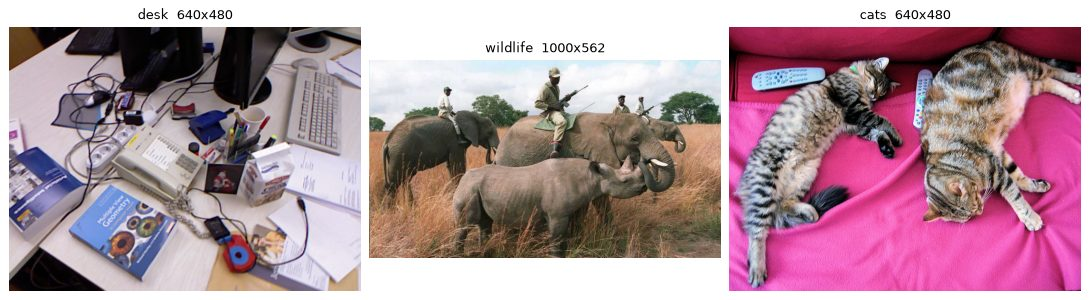

In [2]:
# --- Load the three scenes (RGB uint8) and the COCO ground truth of the cats image ---
desk_seq = load_sequence(cvio.data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk"))
IMAGES = {
    "desk": desk_seq.rgb(100),  # 480x640x3, TUM fr1_desk frame 100
    "wildlife": cvio.read_image(cvio.data_dir("ultralytics", "african-wildlife", "images", "val", "3 (234).jpg")),
    "cats": cvio.read_image(cvio.data_dir("coco", "val2017", "000000039769.jpg")),
}
PROMPTS = {  # the vocabulary we ask for in each scene
    "desk": ["keyboard", "telephone", "book", "mug", "stapler", "computer monitor", "cable"],
    "wildlife": ["rhino", "elephant", "person", "zebra"],
    "cats": ["cat", "remote control", "couch"],
}
# COCO ground truth for the cats image (x, y, w, h -> x1, y1, x2, y2)
coco_val = cvio.load_json(cvio.data_dir("coco", "annotations", "instances_val2017.json"))
cat_names = {c["id"]: c["name"] for c in coco_val["categories"]}
CATS_GT = {}
for a in coco_val["annotations"]:
    if a["image_id"] == 39769:
        x, y, w, h = a["bbox"]
        CATS_GT.setdefault(cat_names[a["category_id"]], []).append([x, y, x + w, y + h])
del coco_val  # 25 MB of JSON we no longer need
print({k: len(v) for k, v in CATS_GT.items()})
fig = viz.show_images(list(IMAGES.values()), [f"{k}  {v.shape[1]}x{v.shape[0]}" for k, v in IMAGES.items()],
                      ncols=3, size=4.0)
ovd.show_jpeg(fig)  # photo grid -> JPEG output (PNG would be ~1 MB)

## 2. Closed-set baseline: YOLO26-s

A closed-set detector ends in a classification layer with a fixed weight matrix
$\mathbf{W} \in \mathbb{R}^{C \times D}$ learned for the $C = 80$ COCO classes. For a region
feature $\mathbf{f}_r \in \mathbb{R}^D$,

$$p(c \mid r) = \sigma\left(\mathbf{w}_c^\top \mathbf{f}_r + b_c\right), \qquad c \in \{1, \dots, C\}.$$

There is no way to ask for anything else: a rhino will either be missed or reported as the
closest COCO class. The cell below runs YOLO26-s with all 80 classes and prints what it
reports in each scene.

desk      ['book', 'cell phone', 'cup', 'keyboard', 'mouse', 'tv']
wildlife  ['elephant', 'person']
cats      ['cat', 'couch', 'remote']


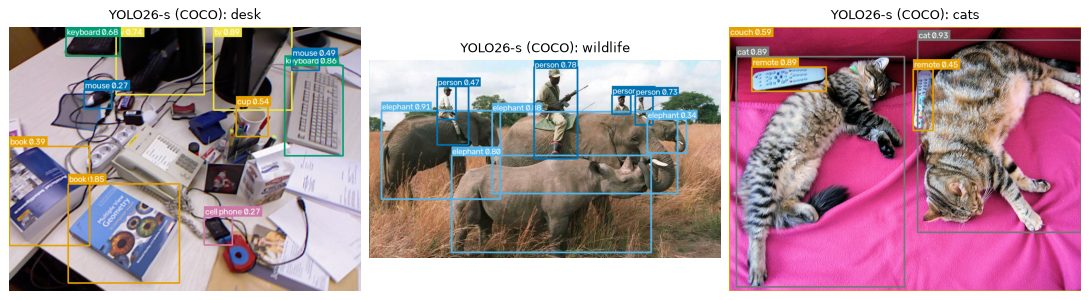

In [3]:
# --- Closed-set detection with all 80 COCO classes ---
# Score threshold 0.25 (the usual YOLO default); boxes are drawn with their COCO class name.
RUNS = {}  # model key -> {"label", "dets": {scene: Detections}, "latency_ms", "peak_mb", ...}
THR = {"yolo26s": 0.25}
det = ovd.load_detector("yolo26s").set_vocabulary(ovd.COCO_NAMES)
closed = {k: det.predict(img, min_score=THR["yolo26s"]) for k, img in IMAGES.items()}
for k, d in closed.items():
    print(f"{k:9s}", sorted(set(d.label_names)))
fig = viz.show_images([viz.draw_boxes(IMAGES[k], d.boxes, d.label_names, d.scores, d.labels)
                       for k, d in closed.items()], [f"YOLO26-s (COCO): {k}" for k in closed],
                      ncols=3, size=4.0)
ovd.show_jpeg(fig)

The closed-set model is good at what COCO covers (keyboard, book, cat, person). It cannot
report the telephone, stapler or cables on the desk, and it labels the rhino with whichever
COCO animal is closest, or misses it. Notebook 02 measures this systematically on the full
african-wildlife validation split.

## 3. Replacing the class matrix with text

Open-vocabulary detectors keep the localisation machinery and replace $\mathbf{W}$ with
**text embeddings** $\mathbf{t}_c = \mathrm{TextEncoder}(\text{prompt}_c)$, computed for
whatever prompts the user gives:

$$s(r, c) = \sigma\left(\alpha\,\frac{\mathbf{f}_r^\top \mathbf{t}_c}{\lVert\mathbf{f}_r\rVert\,\lVert\mathbf{t}_c\rVert} + \beta\right).$$

The region features are trained to align with text on large grounding datasets (Objects365,
GoldG = Flickr30k entities + GQA, V3Det, GRIT, SA-Co, ...). There are two design families:

| family | how text meets the image | text cost | examples |
|---|---|---|---|
| **late fusion** (dual encoder) | dot product at the very end | encode prompts once, cache them | OWLv2, YOLOE |
| **early fusion** (cross-attention) | text tokens and image features attend to each other in the encoder/decoder | the text runs through the fusion layers with every image | Grounding DINO, LLMDet, OmDet-Turbo, SAM 3 |

Early fusion handles phrases ("the mug next to the keyboard") better. Late fusion is cheaper
and its cost does not depend on the vocabulary size. The helper below runs one detector on all
three scenes and records its latency and peak VRAM. Every model gets the same scenes and prompts.

**Thresholds.** Raw scores are not comparable across models (a 0.3 from Grounding DINO is not a
0.3 from OWLv2), so every model gets its own threshold: the score that maximises F1 (IoU 0.5) on
the 200-image COCO subset, measured by `scripts/eval_detectors.py` and stored in
`results/coco_<model>.json` (notebook 02, section 7 explains the curve).

In [4]:
# --- Helper: per-model thresholds, then run one detector on all scenes + latency/VRAM ---
# Latency = end-to-end predict() on the desk image with its 7 prompts (pre/post-processing
# included, CUDA-synchronised). Peak VRAM = torch.cuda.max_memory_allocated() incl. weights.
RESULTS = cvio.project_dir(PROJECT) / "results"
F1_THR = {k: cvio.load_json(RESULTS / f"coco_{k}.json")["f1_curve"]["best_threshold"]
          for k in ovd.MODEL_INFO if k != "yolo26s"}
print("F1-optimal thresholds on the COCO subset:", F1_THR)


def run_open_model(key, thr, masks=False, **kw):
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    det = ovd.load_detector(key, **kw)
    load_s = time.perf_counter() - t0
    out = {"label": det.label, "dets": {}, "load_s": load_s, "vocab_ms": []}
    for scene, img in IMAGES.items():
        t0 = time.perf_counter()
        det.set_vocabulary(PROMPTS[scene])  # text encoding happens here where possible
        out["vocab_ms"].append(1000 * (time.perf_counter() - t0))
        out["dets"][scene] = det.predict(img, min_score=thr, masks=masks)
    det.set_vocabulary(PROMPTS["desk"])
    lat = benchmark(det.predict, IMAGES["desk"], min_score=thr, warmup=3, iters=10)
    out["latency_ms"] = lat["mean_ms"]
    out["peak_mb"] = torch.cuda.max_memory_allocated() / 2**20
    # the first call may also load a text encoder (YOLOE: MobileCLIP2), so report it separately
    out["vocab_first_ms"], out["vocab_ms"] = out["vocab_ms"][0], float(np.mean(out["vocab_ms"][1:]))
    THR[key] = thr
    RUNS[key] = out
    print(f"{det.label}: load {load_s:.1f} s | latency {lat['mean_ms']:.1f} ms | "
          f"peak VRAM {out['peak_mb']:.0f} MiB")
    return det


def show_run(key, scenes=("desk", "wildlife", "cats")):
    r = RUNS[key]
    panels = []
    for s in scenes:
        d = r["dets"][s]
        img = IMAGES[s] if d.masks is None or len(d) == 0 else viz.overlay_masks(
            IMAGES[s], d.masks, alpha=0.4, colors=[viz.color(i) for i in d.labels])
        panels.append(viz.draw_boxes(img, d.boxes, d.label_names, d.scores, d.labels))
    fig = viz.show_images(panels, [f"{r['label']} (score >= {THR[key]}): {s}" for s in scenes],
                          ncols=len(scenes), size=4.0)
    ovd.show_jpeg(fig)

F1-optimal thresholds on the COCO subset: {'yoloe26s': 0.3, 'gdino_t': 0.4, 'llmdet_t': 0.35, 'owlv2_b': 0.25, 'omdet_t': 0.4, 'sam3': 0.7}


## 4. YOLOE-26: text prompts folded into a YOLO head

YOLOE (*Real-Time Seeing Anything*) is a YOLO26 backbone and neck with an embedding head. The
prompts are encoded once by a MobileCLIP2 text encoder. A small *re-parameterisable
region-text alignment* (RepRTA) network refines the embeddings during training. After
`set_classes`, the refined embeddings $\mathbf{T}' = f_\theta(\mathbf{T})$ are **folded into the
weights of the last classification convolution**:

$$\text{logits} = \mathbf{F}\,\mathbf{T}'^\top \;\Rightarrow\; \text{a plain } 1\times1 \text{ conv with weights } \mathbf{T}'.$$

At inference time YOLOE therefore costs about the same as the closed-set YOLO with the same
backbone. The `-seg` checkpoint also predicts instance masks. The text encoder
(`mobileclip2_b.ts`, 254 MB) is loaded from `weights/ultralytics/`.

YOLOE-26-s: load 0.0 s | latency 8.2 ms | peak VRAM 145 MiB


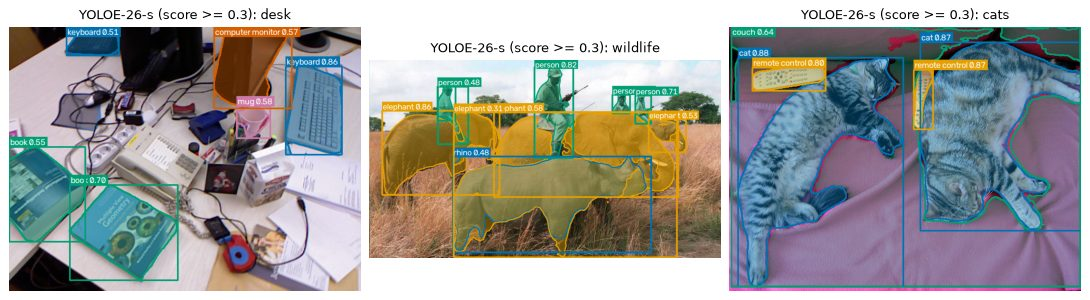

In [5]:
# --- YOLOE-26-s: same prompts, masks included ---
# Threshold = F1-optimal operating point on the 200-image COCO subset (see F1_THR above).
det = run_open_model("yoloe26s", thr=F1_THR["yoloe26s"], masks=True)
ovd.free_detector(det)
show_run("yoloe26s")

## 5. Grounding DINO and LLMDet: a caption and token-level grounding

Grounding DINO concatenates the prompts into one caption, `"keyboard. telephone. book. ..."`,
encodes it with BERT and fuses it with Swin image features through cross-attention in a
*feature enhancer*. The text then **selects the 900 decoder queries** (language-guided query
selection). Each query predicts a box and a logit for **every caption token**
($\mathbf{L} \in \mathbb{R}^{900 \times 256}$), not for every class. A class score is obtained
by averaging over that class's tokens $\mathcal{T}_c$ (the "positive map"):

$$s_{q,c} = \frac{1}{|\mathcal{T}_c|} \sum_{t \in \mathcal{T}_c} \sigma(L_{q,t}).$$

Captions are limited to 256 tokens. The 80 COCO names need 195 BERT tokens and fit in one pass;
larger vocabularies are split into chunks that each need a forward pass. **LLMDet** uses the
same (MM-Grounding-DINO) architecture, trained with captions generated by a large language
model, so the same wrapper runs both. The heatmap shows the raw token probabilities of the
strongest queries on the desk image.

Grounding DINO-T: load 2.1 s | latency 191.1 ms | peak VRAM 1017 MiB


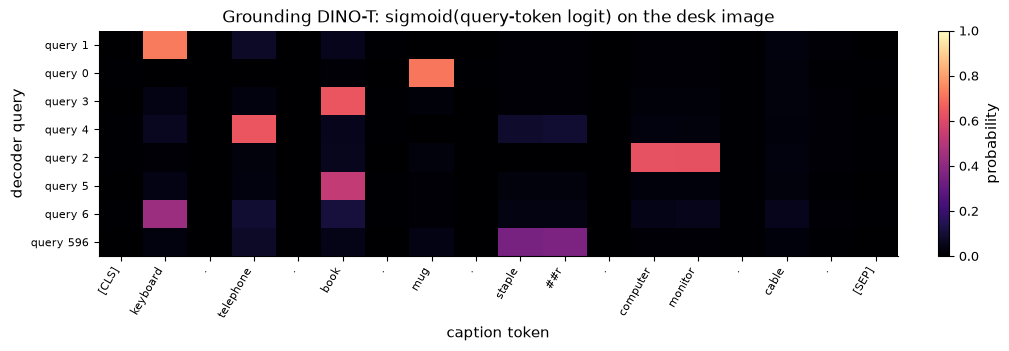

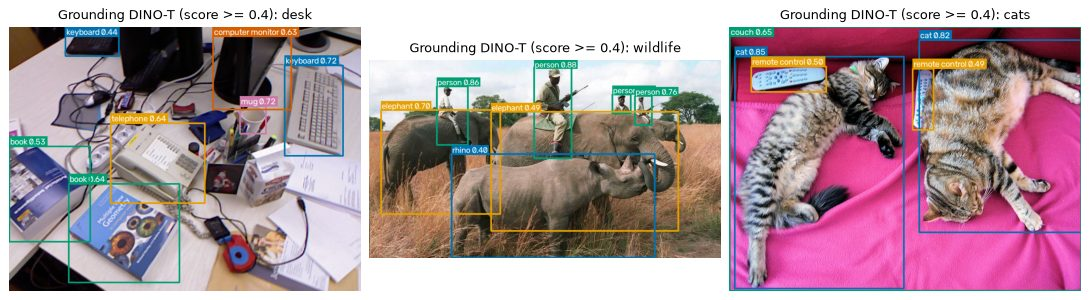

In [6]:
# --- Grounding DINO-T: detections + the raw query x token probability matrix ---
det = run_open_model("gdino_t", thr=F1_THR["gdino_t"])
caption = det.chunks[0]["caption"]  # det still holds the desk vocabulary from the latency run
with torch.inference_mode():
    raw, inputs = det.raw_outputs(IMAGES["desk"], caption)
tokens = det.processor.tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
prob = raw.logits[0].float().sigmoid()[:, : len(tokens)].cpu().numpy()  # (900 queries, T tokens)
top_q = np.argsort(-prob.max(1))[:8]  # the 8 most confident queries
ovd.free_detector(det)

fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(prob[top_q], cmap="magma", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(tokens)), tokens, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(top_q)), [f"query {q}" for q in top_q], fontsize=8)
ax.set_xlabel("caption token")
ax.set_ylabel("decoder query")
ax.set_title("Grounding DINO-T: sigmoid(query-token logit) on the desk image")
ax.grid(False)
fig.colorbar(im, ax=ax, label="probability")
plt.show()
show_run("gdino_t")

Each confident query lights up the tokens of one phrase (both `computer` and `monitor` for the
monitor), and the `.` separators and `[CLS]`/`[SEP]` stay dark. This is why the positive map
averages over a class's tokens. A query that lights up only `computer` would still get half of
the monitor score. LLMDet runs on the same three scenes next.

LLMDet-T: load 1.4 s | latency 201.5 ms | peak VRAM 1065 MiB


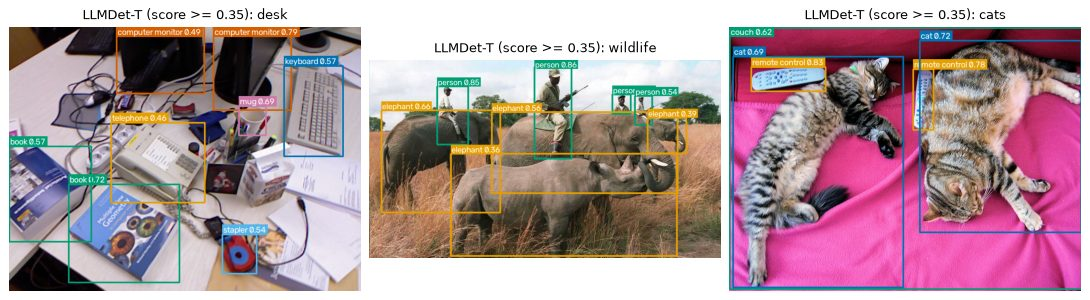

In [7]:
# --- LLMDet-T: same architecture and wrapper, better training data ---
det = run_open_model("llmdet_t", thr=F1_THR["llmdet_t"])
ovd.free_detector(det)
show_run("llmdet_t")

## 6. OWLv2: every image patch is a box proposal

OWLv2 is a CLIP ViT-B/16 with the pooling removed. The image is padded to a square and resized to
960x960 px, which gives $N = (960/16)^2 = 3600$ patch tokens. Each patch $i$ predicts a box
$\mathbf{b}_i$, a class embedding $\mathbf{e}_i$ and a learned shift/scale, and is scored against
every text embedding:

$$s_{i,c} = \sigma\big((\hat{\mathbf{e}}_i^\top \hat{\mathbf{t}}_c + \beta_i)\,\alpha_i\big).$$

Because the text tower is independent of the image, prompt embeddings are computed once and
reused (late fusion). Neighbouring patches often predict nearly the same box, so the wrapper
applies class-wise NMS (IoU 0.5). OWL models were trained with CLIP-style prompts, and the
wrapper uses the template `"a photo of a {}"` by default. Section 8 tests whether that matters.

OWLv2-B/16: load 0.9 s | latency 72.5 ms | peak VRAM 478 MiB
desk, score >= 0.25: 10 boxes without NMS -> 9 after class-wise NMS


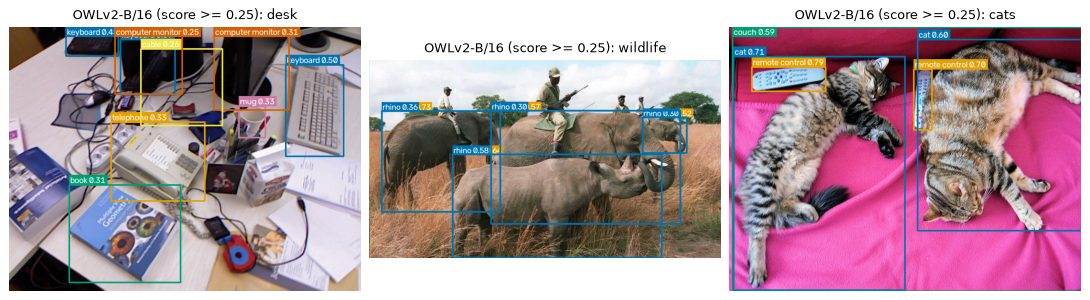

In [8]:
# --- OWLv2-B/16 (ensemble checkpoint) ---
det = run_open_model("owlv2_b", thr=F1_THR["owlv2_b"])
# How many near-duplicate boxes does NMS remove on the desk image?
det.set_vocabulary(PROMPTS["desk"])
det.nms_iou = 0.0  # 0 disables NMS in the wrapper
n_raw = len(det.predict(IMAGES["desk"], min_score=THR["owlv2_b"]))
det.nms_iou = 0.5
n_nms = len(det.predict(IMAGES["desk"], min_score=THR["owlv2_b"]))
print(f"desk, score >= {THR['owlv2_b']}: {n_raw} boxes without NMS -> {n_nms} after class-wise NMS")
ovd.free_detector(det)
show_run("owlv2_b")

## 7. OmDet-Turbo and SAM 3

**OmDet-Turbo** encodes class names and a task sentence ("Detect keyboard, telephone, ...")
separately and caches both. An efficient fusion head mixes them with RT-DETR-style image
features, and NMS is applied at the end. It was designed for real-time open-vocabulary detection.

**SAM 3** (*Segment Anything with Concepts*) does *promptable concept segmentation*: given a short
noun phrase, it returns **every instance** of that concept with a mask. Its DETR-style decoder has
200 object queries plus a separate **presence token** that answers "is this concept in the image
at all?". The final score factorises as

$$s_q = \sigma(\ell_q)\cdot\sigma(\ell_{\text{presence}}),$$

so recognition (is it there?) is separated from localisation (where is it?). SAM 3 takes **one
phrase per forward pass**. The wrapper encodes the image once, encodes every phrase once, and
runs the fusion encoder/decoder for batches of phrases against the cached image features.
This makes SAM 3 much more expensive for large vocabularies (notebook 02).

OmDet-Turbo-T: load 1.7 s | latency 52.0 ms | peak VRAM 370 MiB


SAM 3: load 2.6 s | latency 516.5 ms | peak VRAM 3440 MiB


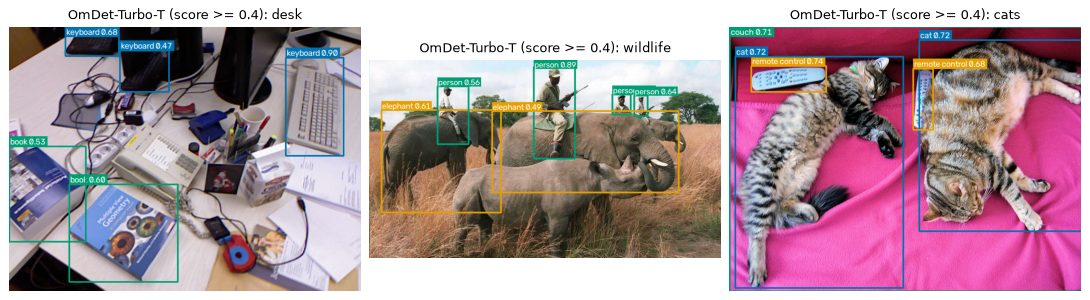

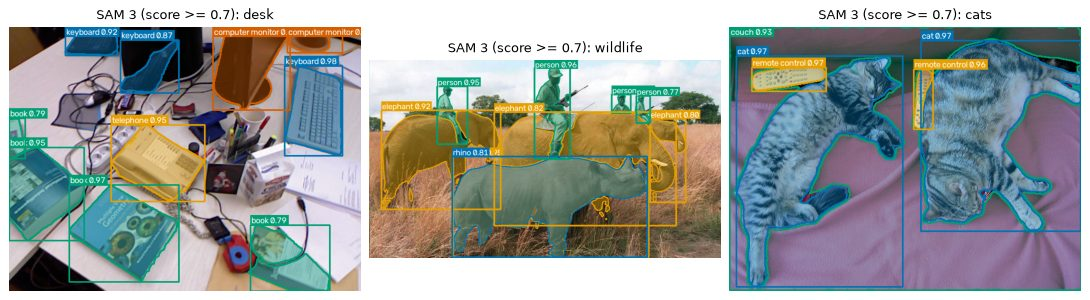

In [9]:
# --- OmDet-Turbo-T and SAM 3 (with masks) ---
det = run_open_model("omdet_t", thr=F1_THR["omdet_t"])
ovd.free_detector(det)
det = run_open_model("sam3", thr=F1_THR["sam3"], masks=True)
ovd.free_detector(det)
show_run("omdet_t")
show_run("sam3")

## 8. Prompt engineering: synonyms, templates and absent objects

Open-vocabulary scores depend on the wording. Two measurements on the cats image, whose COCO
boxes we know:

* **Positive prompts.** For each wording of *cat* or *remote control*, the score of the best
  detection that overlaps a ground-truth box with IoU >= 0.5, averaged over the GT instances
  (0 = not found at all).
* **Absent concepts.** For prompts naming things that are **not** in the image (a dog, a
  laptop, a giraffe, ...), the highest score the model gives to any box. A large value means
  the model would hallucinate that object at a low threshold.

Each prompt is run on its own (vocabulary of size 1), so the prompts do not compete with each
other. The plain wording is sent to every model, with no template.

In [10]:
# --- Prompt sensitivity on the cats image (single-prompt queries) ---
POSITIVE = {"cat": ["cat", "kitten", "tabby cat", "feline", "pet", "animal"],
            "remote": ["remote", "remote control", "tv remote", "clicker", "controller"]}
ABSENT = ["dog", "laptop", "giraffe", "fire hydrant", "person", "pizza"]


def best_gt_score(d, gt_boxes):
    # mean over GT boxes of the max score of a detection with IoU >= 0.5 (0 if none)
    if len(d) == 0:
        return 0.0
    iou = box_iou(np.asarray(gt_boxes, float), d.boxes)  # (n_gt, n_det)
    return float(np.mean([(d.scores * (row >= 0.5)).max() for row in iou]))


rows = []
for key in ["yoloe26s", "gdino_t", "llmdet_t", "owlv2_b", "omdet_t", "sam3"]:
    kw = {"dtype": "bfloat16"} if key == "sam3" else {}
    det = ovd.load_detector(key, template="{}", **kw)  # plain wording for every model
    for target, words in POSITIVE.items():
        for w in words:
            d = det.set_vocabulary([w]).predict(IMAGES["cats"], min_score=0.01)
            rows.append({"model": det.label, "prompt": w, "kind": f"present ({target})",
                         "score": best_gt_score(d, CATS_GT[target])})
    for w in ABSENT:
        d = det.set_vocabulary([w]).predict(IMAGES["cats"], min_score=0.01)
        rows.append({"model": det.label, "prompt": w, "kind": "absent",
                     "score": float(d.scores.max()) if len(d) else 0.0})
    ovd.free_detector(det)
prompt_df = pd.DataFrame(rows)
print(prompt_df.groupby(["kind", "model"])["score"].mean().unstack().round(3))

model             Grounding DINO-T  LLMDet-T  OWLv2-B/16  OmDet-Turbo-T  \
kind                                                                      
absent                       0.126     0.421       0.019          0.295   
present (cat)                0.480     0.739       0.409          0.509   
present (remote)             0.402     0.648       0.499          0.465   

model             SAM 3  YOLOE-26-s  
kind                                 
absent            0.000       0.040  
present (cat)     0.839       0.629  
present (remote)  0.754       0.576  


## Results

The first figure gathers the qualitative detections of every model in one grid (rows: models,
columns: scenes), each at its own threshold, and saves it to `assets/` for the README.

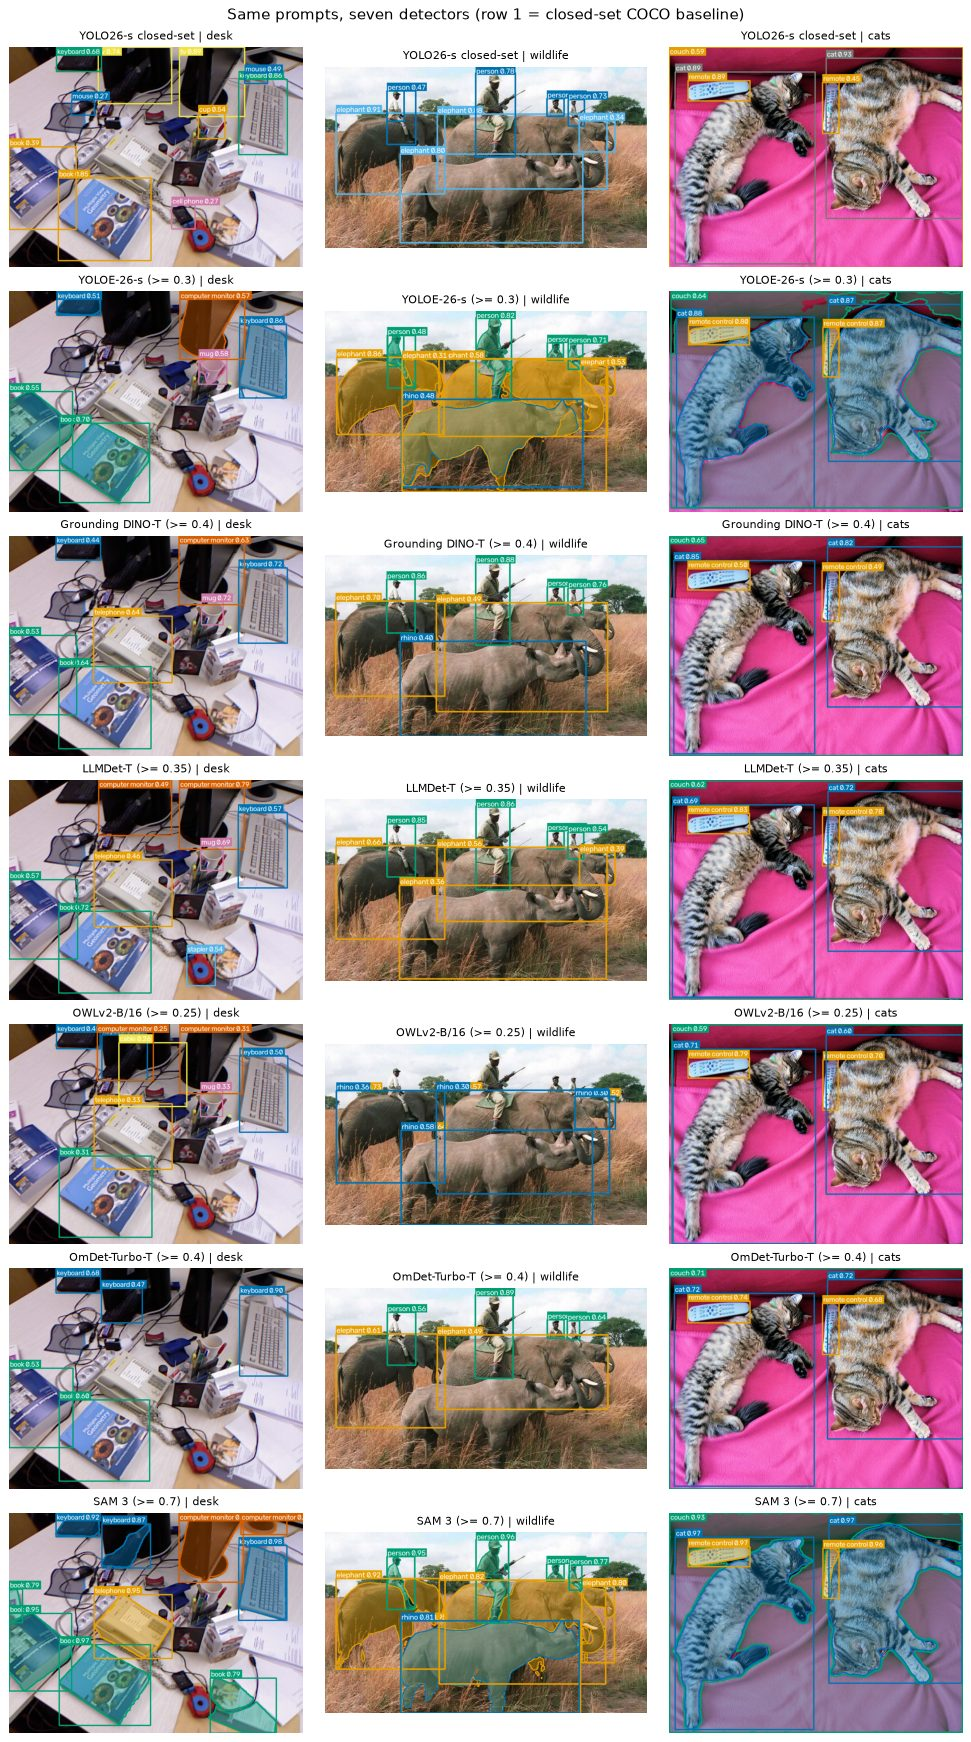

In [11]:
# --- Figure: all models x all scenes (qualitative comparison) ---
order = ["yoloe26s", "gdino_t", "llmdet_t", "owlv2_b", "omdet_t", "sam3"]
scenes = ["desk", "wildlife", "cats"]
fig, axes = plt.subplots(len(order) + 1, 3, figsize=(11, 2.75 * (len(order) + 1)))
for j, s in enumerate(scenes):
    d = closed[s]
    axes[0, j].imshow(viz.draw_boxes(IMAGES[s], d.boxes, d.label_names, d.scores, d.labels))
    axes[0, j].set_title(f"YOLO26-s closed-set | {s}", fontsize=9)
    for i, key in enumerate(order, start=1):
        d = RUNS[key]["dets"][s]
        img = IMAGES[s]
        if d.masks is not None and len(d):
            img = viz.overlay_masks(img, d.masks, alpha=0.4, colors=[viz.color(c) for c in d.labels])
        axes[i, j].imshow(viz.draw_boxes(img, d.boxes, d.label_names, d.scores, d.labels))
        axes[i, j].set_title(f"{RUNS[key]['label']} (>= {THR[key]}) | {s}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Same prompts, seven detectors (row 1 = closed-set COCO baseline)", fontsize=12)
viz.savefig(fig, PROJECT, "model_grid")  # PNG for the README (<= 1 MB)
ovd.show_jpeg(fig)

The prompt-engineering measurements as two heatmaps: scores for wordings of objects that are in
the image (left), and the highest score given to objects that are absent (right).

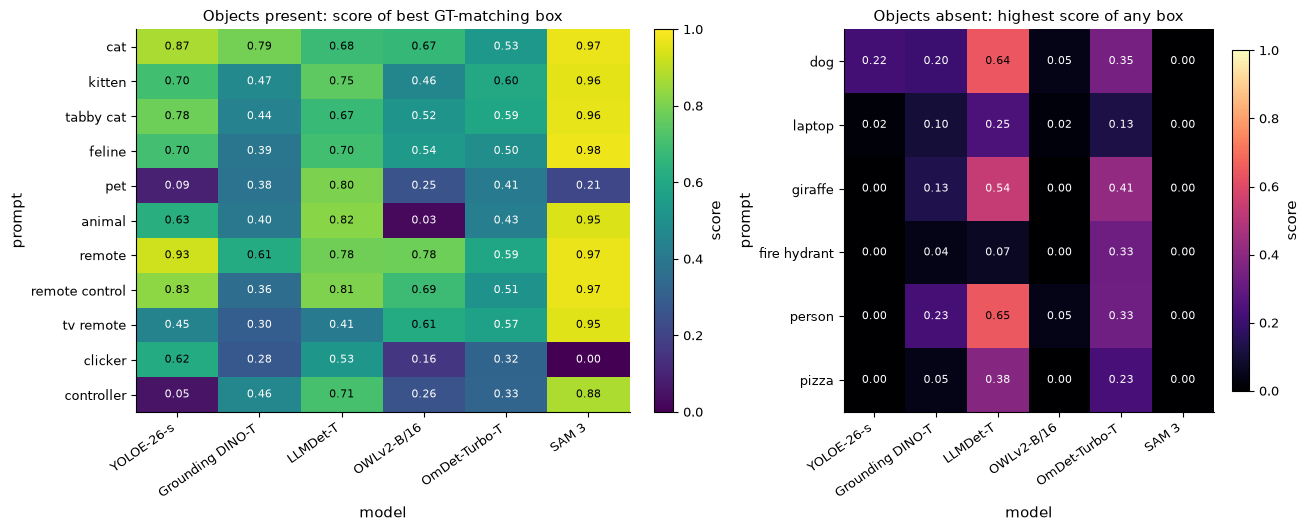

In [12]:
# --- Figure: prompt sensitivity heatmaps (present vs absent concepts) ---
models = [RUNS[k]["label"] for k in order]
pos = prompt_df[prompt_df.kind != "absent"].pivot_table(index="prompt", columns="model", values="score",
                                                        sort=False)[models]
neg = prompt_df[prompt_df.kind == "absent"].pivot_table(index="prompt", columns="model", values="score",
                                                        sort=False)[models]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 0.75]})
for ax, tab, title, cmap in [(axes[0], pos, "Objects present: score of best GT-matching box", "viridis"),
                             (axes[1], neg, "Objects absent: highest score of any box", "magma")]:
    im = ax.imshow(tab.values, cmap=cmap, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(models)), models, rotation=35, ha="right")
    ax.set_yticks(range(len(tab)), tab.index)
    for (r, c), v in np.ndenumerate(tab.values):
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v < 0.6 else "black")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("model")
    ax.set_ylabel("prompt")
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046, label="score")
viz.savefig(fig, PROJECT, "prompt_sensitivity")
plt.show()

Latency and memory measured on the desk image (640x480, 7 prompts), batch size 1, fp16 (bf16
for SAM 3). `set_vocabulary` is timed separately: the first call (desk) and the mean of the two
later calls (wildlife, cats). For the transformers models it only tokenizes or encodes the
prompts. YOLOE is much slower here because Ultralytics' `YOLOE.set_classes` calls
`get_text_pe(..., cache_clip_model=False)`, which **rebuilds the MobileCLIP2 text encoder
(`mobileclip2_b.ts`) on every call**. To switch vocabularies quickly on a robot, encode them once
with `model.model.get_text_pe(names, cache_clip_model=True)` and pass the result to
`model.set_classes(names, embeddings)`, which then only folds the embeddings into the head.

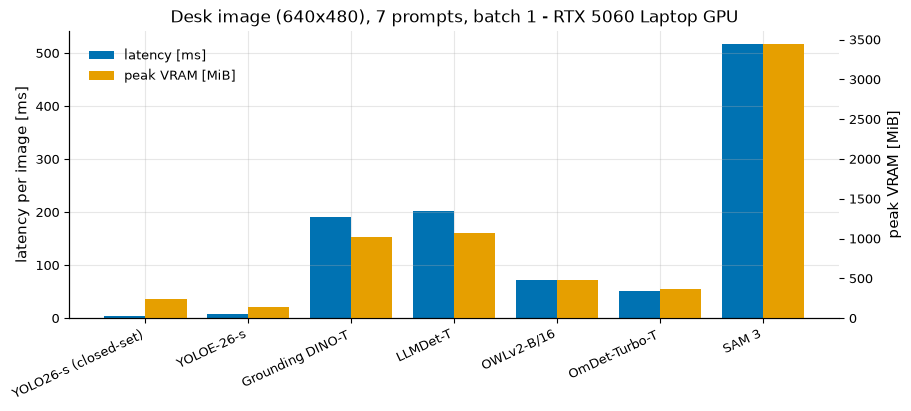

,model,family,latency [ms],FPS,peak VRAM [MiB],1st set_vocabulary [ms],set_vocabulary [ms],threshold,present-object score (mean),absent-object score (mean)
0,YOLO26-s (closed-set),closed-set,4.4,225.0,244,0.0,0.0,0.25,NaN,NaN
1,YOLOE-26-s,late fusion,8.2,121.8,145,398.7,774.4,0.30,0.605,0.040
2,Grounding DINO-T,early fusion,191.1,5.2,1017,0.9,0.2,0.40,0.445,0.126
3,LLMDet-T,early fusion,201.5,5.0,1065,0.3,0.2,0.35,0.697,0.421
4,OWLv2-B/16,late fusion,72.5,13.8,478,2.3,0.9,0.25,0.450,0.019
5,OmDet-Turbo-T,early fusion,52.0,19.2,370,0.0,0.0,0.40,0.489,0.295
6,SAM 3,early fusion,516.5,1.9,3440,101.2,11.2,0.70,0.800,0.000


In [13]:
# --- Figure + table: latency, VRAM and text-encoding cost per model ---
keys = ["yolo26s"] + order
RUNS["yolo26s"] = RUNS.get("yolo26s", {})
# YOLO26-s (closed-set) latency on the same image for reference
torch.cuda.reset_peak_memory_stats()
det = ovd.load_detector("yolo26s").set_vocabulary(ovd.COCO_NAMES)
RUNS["yolo26s"].update(label=det.label, latency_ms=benchmark(det.predict, IMAGES["desk"], warmup=3, iters=10)["mean_ms"],
                       peak_mb=torch.cuda.max_memory_allocated() / 2**20, vocab_ms=0.0, vocab_first_ms=0.0)
ovd.free_detector(det)

summary = pd.DataFrame([{
    "model": RUNS[k]["label"],
    "family": "closed-set" if k == "yolo26s" else ("late fusion" if k in ("yoloe26s", "owlv2_b") else "early fusion"),
    "latency [ms]": round(RUNS[k]["latency_ms"], 1),
    "FPS": round(1000 / RUNS[k]["latency_ms"], 1),
    "peak VRAM [MiB]": round(RUNS[k]["peak_mb"]),
    "1st set_vocabulary [ms]": round(RUNS[k]["vocab_first_ms"], 1),
    "set_vocabulary [ms]": round(RUNS[k]["vocab_ms"], 1),
    "threshold": THR[k],
    "present-object score (mean)": round(prompt_df[(prompt_df.model == RUNS[k]["label"]) & (prompt_df.kind != "absent")].score.mean(), 3) if k != "yolo26s" else np.nan,
    "absent-object score (mean)": round(prompt_df[(prompt_df.model == RUNS[k]["label"]) & (prompt_df.kind == "absent")].score.mean(), 3) if k != "yolo26s" else np.nan,
} for k in keys])

fig, ax1 = plt.subplots(figsize=(9, 4))
x = np.arange(len(summary))
ax1.bar(x - 0.2, summary["latency [ms]"], 0.4, label="latency [ms]", color=viz.color(0, unit=True))
ax2 = ax1.twinx()
ax2.bar(x + 0.2, summary["peak VRAM [MiB]"], 0.4, label="peak VRAM [MiB]", color=viz.color(1, unit=True))
ax1.set_xticks(x, summary["model"], rotation=25, ha="right")
ax1.set_ylabel("latency per image [ms]")
ax2.set_ylabel("peak VRAM [MiB]")
ax2.grid(False)
ax1.set_title("Desk image (640x480), 7 prompts, batch 1 - RTX 5060 Laptop GPU")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
viz.savefig(fig, PROJECT, "latency_vram_desk")
plt.show()
summary

A small thumbnail for the repository README.

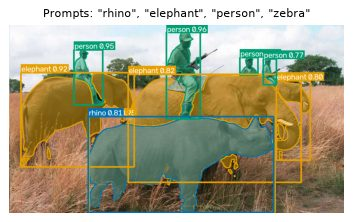

In [14]:
# --- Thumbnail for the root README: SAM 3 concept masks on the wildlife scene ---
d = RUNS["sam3"]["dets"]["wildlife"]
img = viz.overlay_masks(IMAGES["wildlife"], d.masks, alpha=0.45, colors=[viz.color(c) for c in d.labels])
img = viz.draw_boxes(img, d.boxes, d.label_names, d.scores, d.labels)
fig, ax = plt.subplots(figsize=(4.2, 4.2 * img.shape[0] / img.shape[1]))
ax.imshow(img)
ax.axis("off")
ax.set_title('Prompts: "rhino", "elephant", "person", "zebra"', fontsize=9)
viz.savefig(fig, PROJECT, "thumb", dpi=100)
ovd.show_jpeg(fig)

### Takeaways

Measured on one image per scene (desk 640x480 with 7 prompts for timing), single run, RTX 5060
Laptop GPU. These are qualitative observations; notebook 02 has the quantitative benchmark.

* **Speed spans two orders of magnitude.** YOLOE-26-s runs the desk image in 8.2 ms, close to
  the closed-set YOLO26-s (4.4 ms), and is the only open-vocabulary model here that keeps up with
  a 30 Hz camera. OmDet-Turbo-T (52.0 ms) and OWLv2-B/16 (72.5 ms) are interactive, Grounding
  DINO-T (191.1 ms) and LLMDet-T (201.5 ms) run at about 5 FPS, and SAM 3 is the slowest and
  largest (516.5 ms, 3440 MiB peak) but still fits comfortably in 8 GB.
* **Absent objects are the real risk for a robot.** Asked for things that are not in the cats
  image, SAM 3 scores 0.00 for all six (its presence head answers "is it there at all?") and
  OWLv2 at most 0.05. LLMDet-T gives 0.64 to *dog*, 0.65 to *person* and 0.54 to *giraffe*, and
  OmDet-Turbo-T 0.41 to *giraffe*: all above those models' own thresholds (0.35 and 0.40), so they
  would report objects that do not exist. LLMDet's high scores for vague words (*pet* 0.80,
  *animal* 0.82) come from the same eagerness.
* **Wording matters, and differently for each model.** SAM 3 scores at least 0.88 for 9 of the 11
  wordings of *cat* and *remote*, but 0.00 for *clicker* and 0.21 for *pet*. OWLv2 gives 0.03 to
  *animal*, YOLOE 0.05 to *controller*. Prefer common, concrete nouns and test the exact
  vocabulary a robot will use on its own camera images.
* **Every model needs its own threshold.** The F1-optimal COCO thresholds range from 0.25
  (OWLv2) to 0.70 (SAM 3). One global threshold would make some models look blind and others
  noisy.
* **Changing the vocabulary is cheap except for YOLOE in Ultralytics**: 398.7 ms for the first
  `set_vocabulary` and 774.4 ms on average for the later ones, because the text encoder is
  rebuilt on every call (see the note above the latency table). After their first call the
  transformers models need at most 11.2 ms (SAM 3).

## Exercises

Solutions: `projects/04_open_vocab_detection/solutions/`.

**Exercise 1: your own vocabulary on a robot frame.** Frame 500 of the desk sequence
(`desk_seq.rgb(500)`) shows a game controller, a cereal box and a telephone cord. Write
prompts for these objects and find, for two models of your choice, the lowest threshold at
which no false positives appear. How far apart are the thresholds of the two models?

In [15]:
# --- Exercise 1 (TODO): prompts for desk frame 500 ---
frame = desk_seq.rgb(500)
my_prompts = ["game controller"]  # TODO: add more objects you can see in the frame
# TODO: for two detectors, run det.set_vocabulary(my_prompts).predict(frame, min_score=t)
#       for t in np.arange(0.1, 0.9, 0.05) and plot the number of boxes vs t.

**Exercise 2: visual prompts instead of words.** Some objects are hard to name ("the blue
thing"). YOLOE also accepts a **visual prompt**: a box around an example object in a reference
image. Take the telephone box in desk frame 100 from one of the text-prompted runs above (YOLOE
itself may miss it at its threshold, so use e.g. `RUNS["llmdet_t"]`), use it as a visual prompt
and detect telephones in frame 300. Hint: `YOLOE.predict(..., visual_prompts={"bboxes": np.array([[x1, y1, x2, y2]]),
"cls": np.array([0])}, predictor=YOLOEVPSegPredictor, refer_image=ref_bgr)`.

In [16]:
# --- Exercise 2 (TODO): YOLOE visual prompts ---
from ultralytics.models.yolo.yoloe import YOLOEVPSegPredictor  # noqa: F401  (used in your solution)

ref, target = desk_seq.rgb(100), desk_seq.rgb(300)
# TODO: take the telephone box from RUNS["llmdet_t"]["dets"]["desk"], build the visual prompt,
#       run it on `target` and draw the result.

**Exercise 3: prompt ensembling for OWLv2.** CLIP-style models do better when the text
embedding is averaged over several templates ("a photo of a {}", "a close-up photo of a {}",
"a {} in a scene", ...). Build an ensemble embedding for each class, L2-normalise it, and
compare the present/absent scores on the cats image with the single-template version from
section 8. Hint: `det.model.owlv2.get_text_features` and `det.model.class_predictor`.

In [17]:
# --- Exercise 3 (TODO): OWLv2 prompt ensembling ---
templates = ["a photo of a {}", "a close-up photo of a {}", "a photo of the {}", "a {} in a scene"]
# TODO: encode every template for every class, average the normalised embeddings per class,
#       then score the image patches against the ensemble embeddings.